# Numerical Comparison with Continuous Black-Scholes Model

## The Continuous Black-Scholes Model (with no dividend yield)
Now that we have our discrete time model, we will compare it with the continuous time model with Black-Scholes.

The Black-Scholes price formula for a European Call option (with no dividend yield) is:

$$C=S\Phi(d_1)-Ke^{-rT}\Phi(d_2)$$

where $S$ is the current underlying price, $K$ is the strike price, $r$ is the market risk-free rate, $T$ is time until maturity, $\sigma$ is annualized volatility, $d_1=\frac{\ln(S/K)+(r+\sigma^2/2)T}{\sigma\sqrt{T}}$ and $d_2=d_1-\sigma\sqrt{T}$. Note that $\Phi$ denotes the standard normal cumulative distribution function accessible using `scipy.stats.norm.cdf`. For the price of a put-option, we can use the fact that for European-style options, the price of a put option is related to the price of the call option by:

$$C-P=S-Ke^{-rT}\implies P = C-(S-Ke^{-rT})$$

and one can show that the following will be true:

$$P=Ke^{-rT}\Phi(-d_2)-S\phi(-d_1)$$

For American-style options, this model will still generate the correct price EXCEPT when it comes to American put options. The reason is because American call options don't benefit from exercising early as the time-value of the option will essentially be wasted; more details in the [README](../README.md#why-american-style-calls-never-benefit-from-early-exercising-assuming-no-dividends). However, put options are different as oppotunities where the stock price drops below the strike price can have more value than waiting until maturity.

## The Black-Scholes Model (with dividend yield)

The Black-Scholes formula for a European Call option (with dividend yield $q_d$) is:

$$C=Se^{-q_dT}\Phi(d_1)-Ke^{-rT}\Phi(d_2)$$

where $d_1=\frac{\ln(S/K)+(r-q+\sigma^2/2)T}{\sigma\sqrt{T}}$ and $d_2=d_1-\sigma\sqrt{T}$. For a European Put options, similar to above one can show that

$$P=Ke^{-rT}\Phi(-d_2)-Se^{-q_dT}\Phi(-d_1)$$

For American-style options with dividend yield, we cannot use this model as early exercising of the option can become optimal for both call and put options. The reason why exercising an American call option is now viable with dividends, is because you can exercise the contract right before an ex-dividend date so you can receive that dividend from your bought stock; this dividend payout can possibly make the overall profit higher than the remaining time-value of the option.

### Import appropriate modules

In [1]:
from pathlib import Path
import sys

# Get the directory of the notebook, navigate up, and find 'src'
src_path = Path.cwd().parent / "src"

# Add to system path if it's not already there
if str(src_path) not in sys.path:
    sys.path.append(str(src_path))

# Import the other modules
import numpy as np 
import matplotlib.pyplot as plt
from scipy.special import binom

# The discrete model
from binomial_option_pricer import binomial_option_pricer, call_payoff, put_payoff

# Import the Black-Scholes Model
from black_scholes_pricer import black_scholes_price

### Input Tree Parameters

In [13]:
S = 300
K = 250
T = 1
N = 100

sigma = 0.5
r = 0.02
call = True
european = True
q_d = 0
A = binomial_option_pricer(S=S, K=K, T=T, N=N, sigma=sigma, r=r, q_d=q_d, call=call, european=european)

### Checking the No-Arbitrage Rule

In [14]:
R = np.exp(r*T/N)
u = np.exp(sigma*np.sqrt(T/N))
d = 1/u
q = (np.exp((r-q_d)*T/N)-d)/(u-d)

print(f"d = {d}")
print(f"R = {R}")
print(f"u = {u}")
print(f"q = {q}")

if q_d == 0:
    if R <= d:
        raise ValueError("Arbitrage opportunity (R <= d): Borrow money at the market risk-free rate and put it into the stock")
    elif R >= u:
        raise ValueError("Arbitrage opportunity (R >= u): Short-sell the stock and put that money in an investment returning the market risk-free rate")
    else:
        print("No-Arbitrage Rule not violated!")
else:
    if q <= 0 or q >= 1:
        raise ValueError("Risk-neutral probability is not a valid probability")
    else: print("No-Arbitrage Rule not violated!")


d = 0.9512294245007139
R = 1.0002000200013335
u = 1.0512710963760241
q = 0.48950197035546794
No-Arbitrage Rule not violated!


### Numerical Comparison

The following code plots the convergence of the discrete-time model to the true Black-Scholes option price as the number of time-steps $N$ increases. The right plot shows the absolute error between the discrete-time option value to the true Black-Scholes option value versus the number of time-steps $N$ in a log-log plot.

Text(0, 0.5, 'Absolste Error')

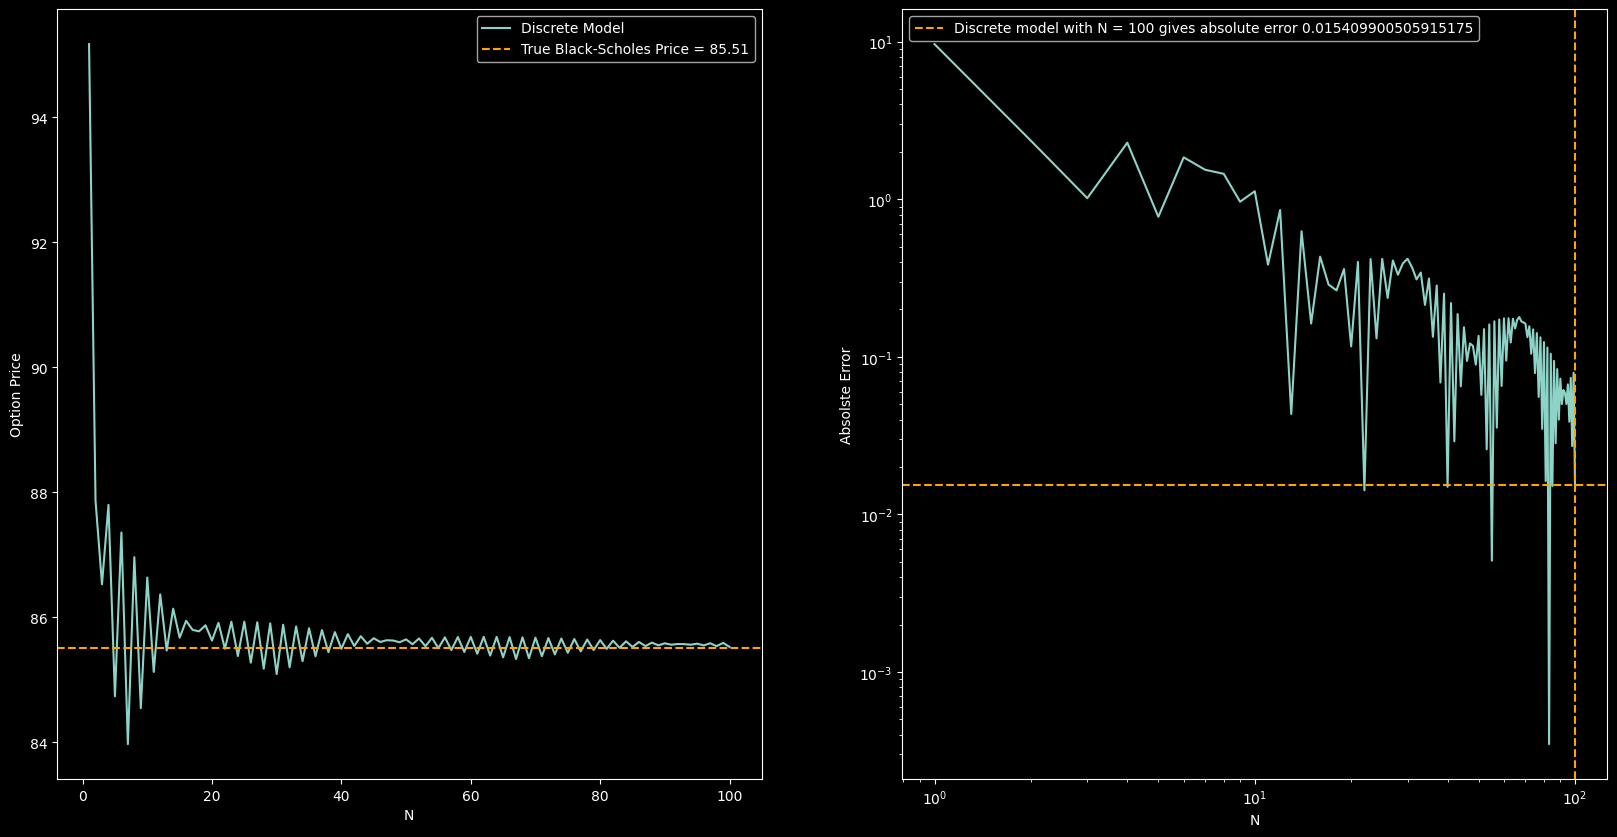

In [15]:
# Make sure option NOT American put
assert(european or call)

# If there is dividends, make sure option is not American
if q_d != 0: assert(european)

# Our baseline Black-Scholes price that are discrete model should converge to as N increases
true_V = black_scholes_price(S=S,K=K,r=r,T=T,q_d=q_d,sigma=sigma,call=call)

# Maximum value of N; keep under 1000 for binomial coefficient computation overflow
maxN = 100

# Setup plotting
plt.style.use('dark_background')
fig,ax = plt.subplots(1,2,figsize=(20,10))

# Generate our X_data which is N-values, and Y_data containing our option prices
X_data = np.array(range(1,maxN+1))
Y_data = np.zeros(maxN)

if call: g = call_payoff
else: g = put_payoff

for i in range(1,maxN+1):
    R = np.exp(r*T/i)
    u = np.exp(sigma*np.sqrt(T/i))
    d = 1/u
    q = (np.exp((r-q_d)*T/i)-d)/(u-d)
    Y_data[i-1] = 1.0/R**i * np.sum([(binom(i,j) * q**j * (1-q)**(i-j) * g(K, S * u**j * d**(i-j))) for j in range(i+1)])

# Show convergence of discrete model to continuous model
ax[0].plot(X_data,Y_data,label="Discrete Model")
ax[0].axhline(y=true_V, color="orange",linestyle="--",label=f"True Black-Scholes Price = {true_V:.2f}")
ax[0].set_xlabel("N")
ax[0].set_ylabel("Option Price")
ax[0].legend()

# Show how the absolte error changes vs N
Y_data = np.abs(Y_data - true_V)
ax[1].plot(X_data,Y_data)
ax[1].axvline(x=N,color="orange",linestyle="--",label=f"Discrete model with N = {N} gives absolute error {abs(true_V-A.V0)}")
ax[1].axhline(y=abs(true_V-A.V0),color="orange",linestyle="--")
ax[1].legend()
ax[1].set_yscale("log")
ax[1].set_xscale("log")
ax[1].set_xlabel("N")
ax[1].set_ylabel("Absolste Error")

### Some Observations

For smaller maxN values you can see that the discrete model oscillates around the true Black-Scholes price in a saw-tooth-like manner. The reason is because as we increment the $N$-value, the placement of the terminal nodes relative to the strike price $K$ changes. Because the terminal nodes represent the payoff when the stock price is of the form $S_0u^jd^{N-j}$ and $d=1/u$, there will exist a node at $S_0$ when $N$ is even, but for odd $N$, nodes can only be close to $S_0$. Because the payoff function for a call option is $\max(S_T-K,0)$ has a kink (sharp corner or abrupt change in slope) at $S_T=K$, small changes to the placement of terminal nodes as $N$ increases and change between odd/even can cause abrupt changes to the resulting discrete model price, hence the saw-tooth oscillations. But despite these oscillations, convergence of the discrete model to the Black-Scholes model is observed. 

For the case when $S_0=K$, the placement of $K$ relative to the terminal nodes stay consistent as $N$ increases, leading to a smooth decay in the oscillations as $N$ increases. However, in the case when $S_0\neq K$ the change in placements of the terminal nodes as $N$ increases also causes some irregular "beating" in the oscillations. Since $S_0\neq K$, the placement of $K$ relative to the terminal nodes is not in the center anymore, but off to one side. Since the price increment between the terminal nodes is a factor of $u/d=e^{2\sigma\sqrt{T/N}}$ the log-price increment between the terminal nodes become proportional to $\sigma\sqrt{T/N}$. Since the log-price increment is not linear with $N$, the grid of the terminal nodes' log-price $\ln(S_0u^jd^{N-j})$ will drift past the fixed point $\ln(K)$. This phenomena plus the kink in the payoff function for the option, as $N$ increases, causes the cycle of spikes in the amplitudes of the oscillations (when a terminal node is very close to $K$) and settling near the Black-Scholes price (when $K$ is about halfway between two terminal nodes).